# Surrogate Models

## 1. Linear Regression with One Variable

Imagine we want to derive a linear regression model that approximates the relationship between the yield
strength and tensile strength values of a dataset based on experiments on polymeric materials. The dataset presents samples where yield strength and tensile strength values liespectively in the ranges (1MPa - 25MPa) and (1MPa - 23MPa).

### 1.1 Plotting the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# This is to set the style of the plots to be more visually appealing
plt.style.use('default')
plt.style.use('seaborn-v0_8-darkgrid')
plt.style.use('seaborn-v0_8-poster')

In [2]:
# Import the data from the text file and assign column names
df = pd.read_csv('data.txt', sep=',', header=None)
df.columns = ['yield_strength', 'tensile_strength']

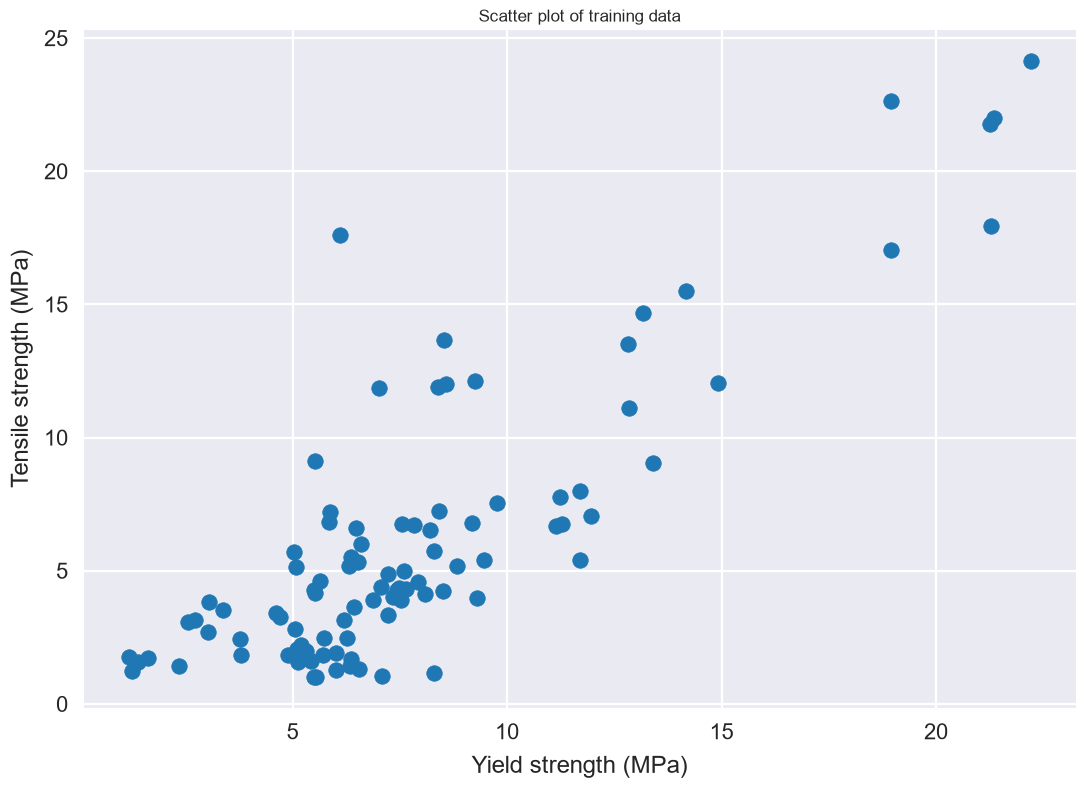

In [3]:
# ---- plot
fig = plt.figure()
ax = fig.add_subplot(111)
ax.scatter(df['yield_strength'],df['tensile_strength'])
# -- labels
ax.set_xlabel('Yield strength (MPa)',labelpad=8)
ax.set_ylabel('Tensile strength (MPa)',labelpad=8)
plt.title('Scatter plot of training data', fontsize = 12)

plt.show()

The plot shows that they _might_ have a linear relationship.

## Exercise 1

Implement the closed-form solution to find the $\beta$ coefficients of the linear regression model.

$$\hat{\beta} = (X^TX)^{-1}X^Ty$$

In [4]:
X = df['yield_strength'].to_numpy()
y = df['tensile_strength'].to_numpy()

In [5]:
# Implement a function to apply the closed form formula above
                                                      
def closed_form_LSQE(X:np.ndarray, y:np.ndarray):
    r"""
    Compute the least squares solution using the closed-form formula.
    
    Parameters:
    X (np.ndarray): The design matrix.
    y (np.ndarray): The target values.
    
    Returns:
    np.ndarray: The least squares solution.
    """
    #
    ##### TODO: Enter your code here:
    return np.dot(np.dot(np.linalg.inv(np.dot(np.transpose(X),X)),np.transpose(X)),y)
    #####

In [6]:
Xe = np.hstack((np.ones((len(X),1)),X.reshape(len(X),1)))
beta_e = closed_form_LSQE(Xe, y)
print("Estimated coefficients: ")
print(f"Intercept: {beta_e[0]}, Slope: {beta_e[1]}")

Estimated coefficients: 
Intercept: -1.7730748919191726, Slope: 1.0132009711213927


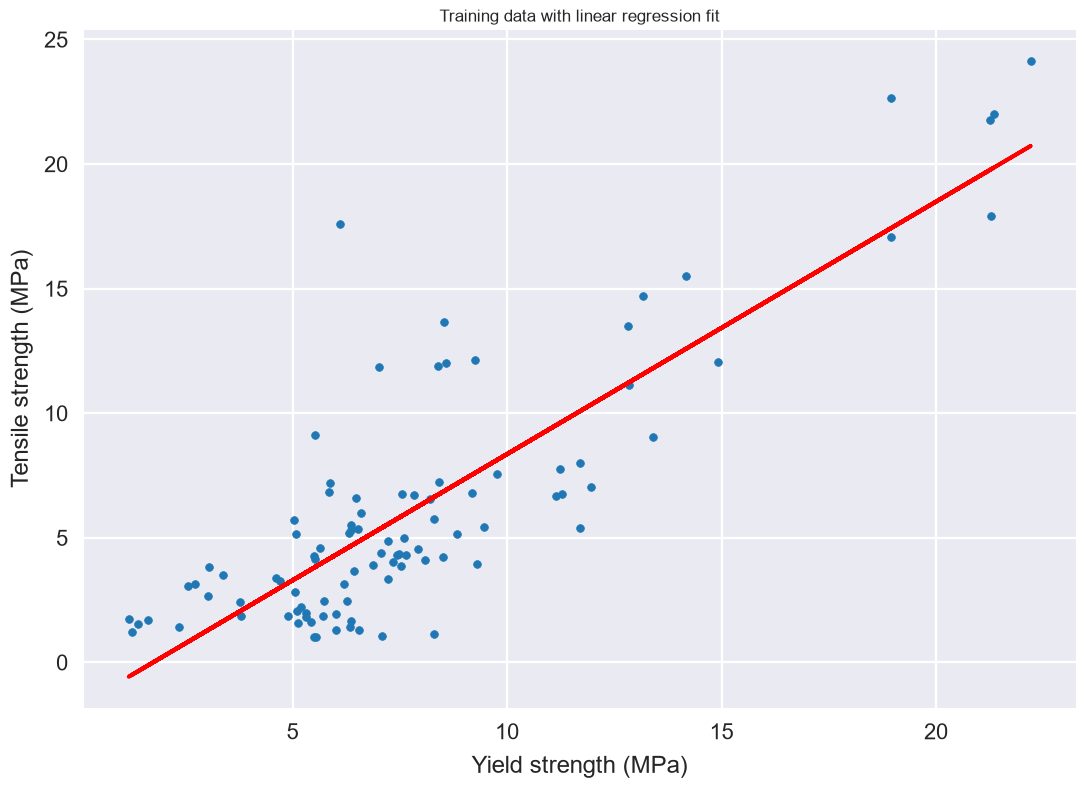

In [7]:
# Plotting results (scatter plot plus linear fit)

# ---- plot
fig = plt.figure()
ax = fig.add_subplot(111)

##### TODO:Enter your code here:

# Plot the scatter plot
ax.scatter(X,y,marker='.')

# Plot the regression
y_hat = Xe@beta_e
ax.plot(X,y_hat,'r')
##### END of code

# -- labels
ax.set_xlabel('Yield strength (MPa)',labelpad=8)
ax.set_ylabel('Tensile strength (MPa)',labelpad=8)
plt.title('Training data with linear regression fit', fontsize = 12)

plt.show()




## Exercise 2: Solution Code using Scikit-Learn

Scikit-Learn has a method which performs linear regression for you. Use the `fit` method from the class `LinearRegression` to find the same solution as the one found implementing the closed-form formula (print the intercept and coefficient beta values to screen to check).

If you don't have the package installed, add it by activating your environment and running `conda install scikit-learn` or `pip install scikit-learn` on your shell.


In [8]:
# Train the scikit-learn linear regression model.
# X must be reshaped to a 2D feature matrix.

from sklearn.linear_model import LinearRegression

##### TODO: Enter your code here:
reg = LinearRegression().fit(X.reshape(-1, 1), y.reshape(-1, 1))

print("Estimated coefficients from SciKit-Learn: ")
print(f"Intercept: {reg.intercept_.ravel()[0]}, Slope: {reg.coef_.ravel()[0]}")

##### END of code

Estimated coefficients from SciKit-Learn: 
Intercept: -1.77307489191917, Slope: 1.0132009711213932


## 2. Assess Meta-model Quality

One of the quality metrics for regression models we have seen is the Coefficient of Determination $R^2$. It helps determine how well the model is blend and how well the output value is explained by the determining (independent) variables of the dataset.The closer the value to 1, the best the model prediction. Let's remember the formula:

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

where 
- $SS_{res}$ represents the sum of squares of the residual errors of the data model.
- $SS_{tot}$ represents the total sum of the errors.






## Exercise 3
### Part 1
Code the $R^2$ formula above. Take 15 random points from the data used in Exercise 1 and compute $R^2$ based on those.

In [9]:
def my_coefficient_determination(y, pred):
    ##### TODO: Enter your code here:
    # Compute the sum of squares of residual errors
    sst = np.sum(np.power((y.reshape(-1,1)-np.mean(y.reshape(-1,1))),2))
    sse = np.sum(np.power((y.reshape(-1,1)-pred.reshape(-1,1)),2))
    return (1-sse/sst)
    
    ##### End of code


In [10]:
# Extracting 15 random points from the sample and computing approximated values

##### TODO: Enter your code here:
rng = np.random.default_rng(seed=21)
# Enter the random mask
random_mask = np.sort(rng.choice(len(y), 15, replace=False))
print(random_mask)

# Slice the arrays
y_rand = y[random_mask]

y_pred = reg.predict(X.reshape(-1,1)[random_mask])


##### End of code

# Computing coefficient of determination value
r = my_coefficient_determination(y_rand,y_pred)
print('Coefficient of Determination:', r) 


[ 8 23 25 26 30 32 40 52 57 58 62 65 91 92 95]
Coefficient of Determination: 0.8040902042752676


The value for $R^2$ is quite low, meaning that the linear model is not suitable for approximating the data or that the measures are affected by severe noise.

### Part 2
Sklearn has the built-in method `r2_score` to compute the coefficient of determination. Use it to verify that you did not make any mistakes in the first part of the exercise. 

In [11]:
##### TODO:Enter your code here:
from sklearn.metrics import r2_score
R_square = r2_score(y_rand, y_pred)

##### End of code

print('Coefficient of Determination from Scikit-learn:', R_square) 

Coefficient of Determination from Scikit-learn: 0.8040902042752676


## 3. Polynomial models of different degrees

We now see an example from Scikit-learn about polynomial models of different degrees and how they approximate the data. We will see that a linear function (polynomial with degree 1) is not sufficient to fit the training samples (UNDERFITTING). A polynomial of degree 4 approximates the true function almost perfectly. Instead, for higher degrees the model OVERFITS the training data, i.e., it learns the noise of the training data. 

The quality of the models is evaluated by using cross-validation with 10 folds.

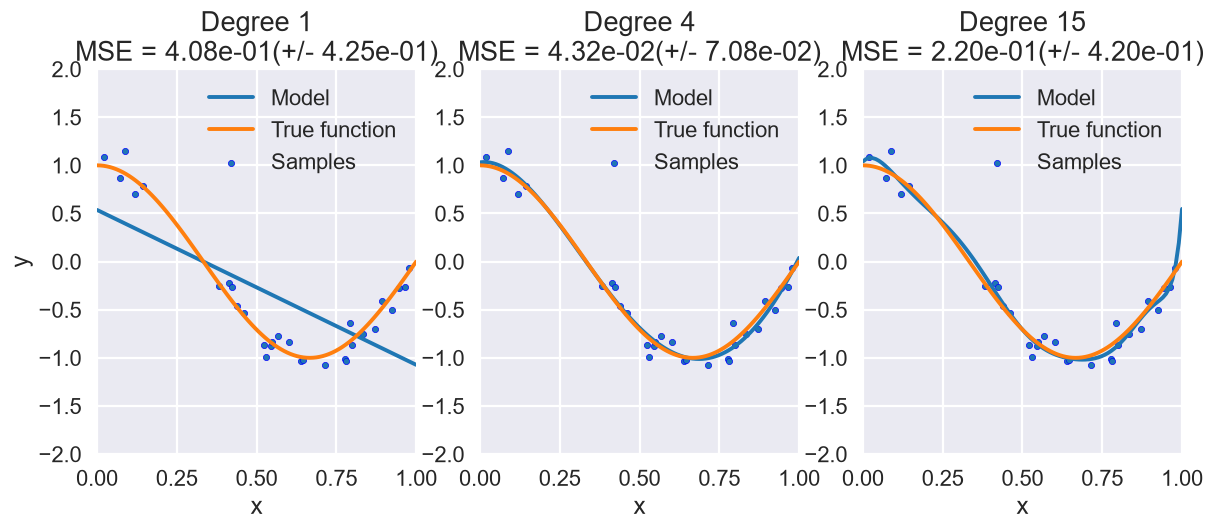

In [12]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


def true_fun(X: np.ndarray) -> np.ndarray:
    return np.cos(1.5 * np.pi * X)

# Initialization of random seed
np.random.seed(0)

n_samples = 30
degrees = [1, 4, 15]

# Adding noise to the true function to generate our sample
X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(14, 5))
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    # plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i], include_bias=False)
    linear_regression = LinearRegression()
    pipeline = Pipeline(
        [
            ("polynomial_features", polynomial_features),
            ("linear_regression", linear_regression),
        ]
    )
    # Fitting the estimator
    pipeline.fit(X[:, np.newaxis], y)

    # Evaluate the models using cross validation
    scores = cross_val_score(
        pipeline, X[:, np.newaxis], y, scoring="neg_mean_squared_error", cv=10
    )

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model")
    plt.plot(X_test, true_fun(X_test), label="True function")
    plt.scatter(X, y, edgecolor="b", s=20, label="Samples")
    plt.xlabel("x")
    if i == 0:
        plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title(
        "Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(
            degrees[i], -scores.mean(), scores.std()
        )
    )
plt.show()

In [13]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from mpl_toolkits.mplot3d import Axes3D

In [14]:
def forrester(x):
    # 1D example function to illustrate Gaussian process

    # Scale from [-5, 5] to [0, 1]
    x_scale = (x + 5) / 10
    return (6*x_scale-2)**2 * np.sin(12*x_scale-4)

def gramacy_lee(x): 
    # 1D example function to illustrate Gaussian process

    # Scale from [-5, 5] to [0.5, 2.5]
    x_scale = (x + 5) / 10 * 2 + 0.5
    return np.sin(10 * np.pi * x_scale) / (2 * x_scale) + (x_scale - 1)**4

def schwefel(x):
    # 1D example function to illustrate Gaussian process

    #Scale from [-5, 5] to [-500, 500]
    x_scale = (x + 5) / 10 * 1000 - 500
    return 418.9829 * 1 - x_scale * np.sin(np.sqrt(np.abs(x_scale)))

def sphere(x):
    # 1D example function to illustrate Gaussian process

    x_scale = x.copy()
    return x_scale**2 

def rastrigin(x):
    # 1D example function to illustrate Gaussian process

    #Scale from [-5, 5] to [-5.12, 5.12]
    x_scale = (x + 5) / 10 * 10.24 - 5.12
    return 10 + x_scale**2 - 10 * np.cos(2 * np.pi * x_scale)   


#TODO: Pick one function to be used for the surrogate model
f = gramacy_lee

In [15]:
#Euclidean norm in R^n
def euclidean_norm(x1, x2):
    return np.sqrt(np.sum(np.power(x1 - x2, 2)))

Commonly used types of radial basis functions include:

- Gaussian kernel: $ \varphi (r) = e^{-\frac{(\varepsilon r)^{2}}{2L^2}} $
- Multiquadric kernel: $ \varphi (r) = \sqrt{1+(\varepsilon r)^{2}} $
- Inverse quadratic kernel: $ \varphi (r) = \frac{1}{1+(\varepsilon r)^{2}}  $
- Inverse multiquadric kernel: $ \varphi (r) = \frac{1}{\sqrt{1+(\varepsilon r)^{2}}}  $

where $r$ is the distance from the center of the basis and $\varepsilon$ is a shape parameter that can be used for scaling the input of the kernel.

## Exercise 4
- Implement the isotropic kernels above, taking the radius as input and returning the value of the basis at the given radius (i.e., distance from the center of the basis). 
- By trying out several values for $\varepsilon$, observe how the plot of the kernel functions changes and find the value returning the plot below.

!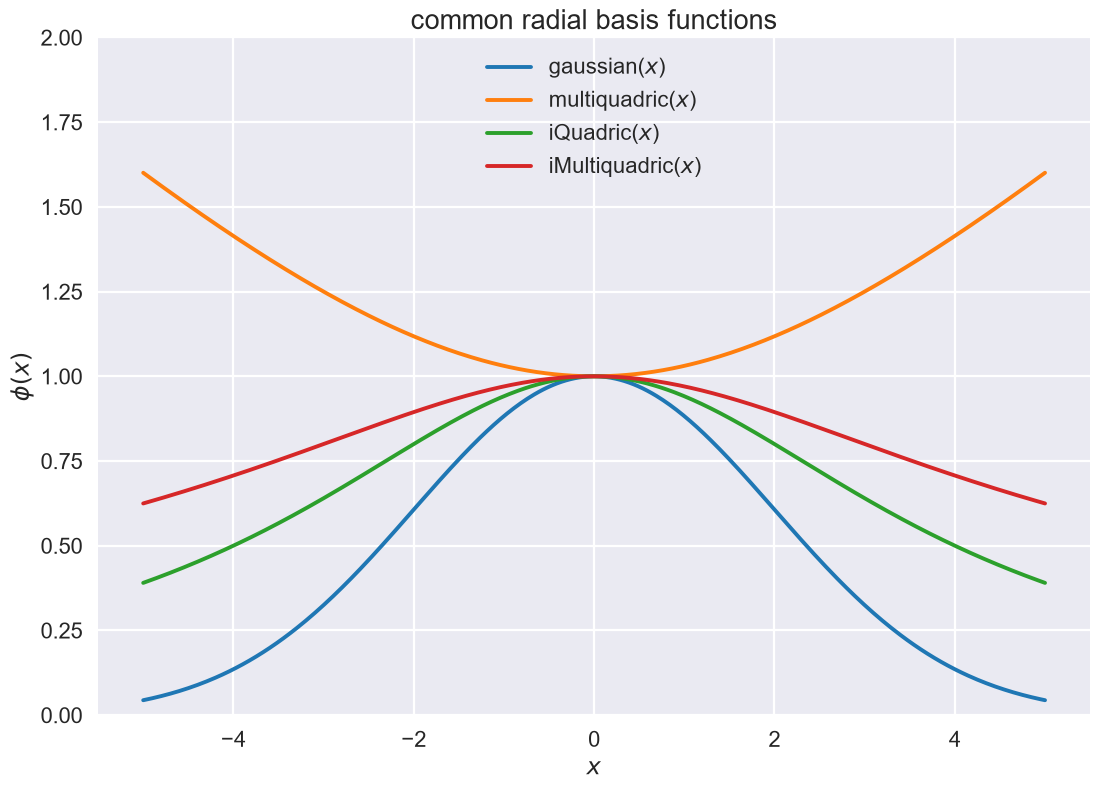

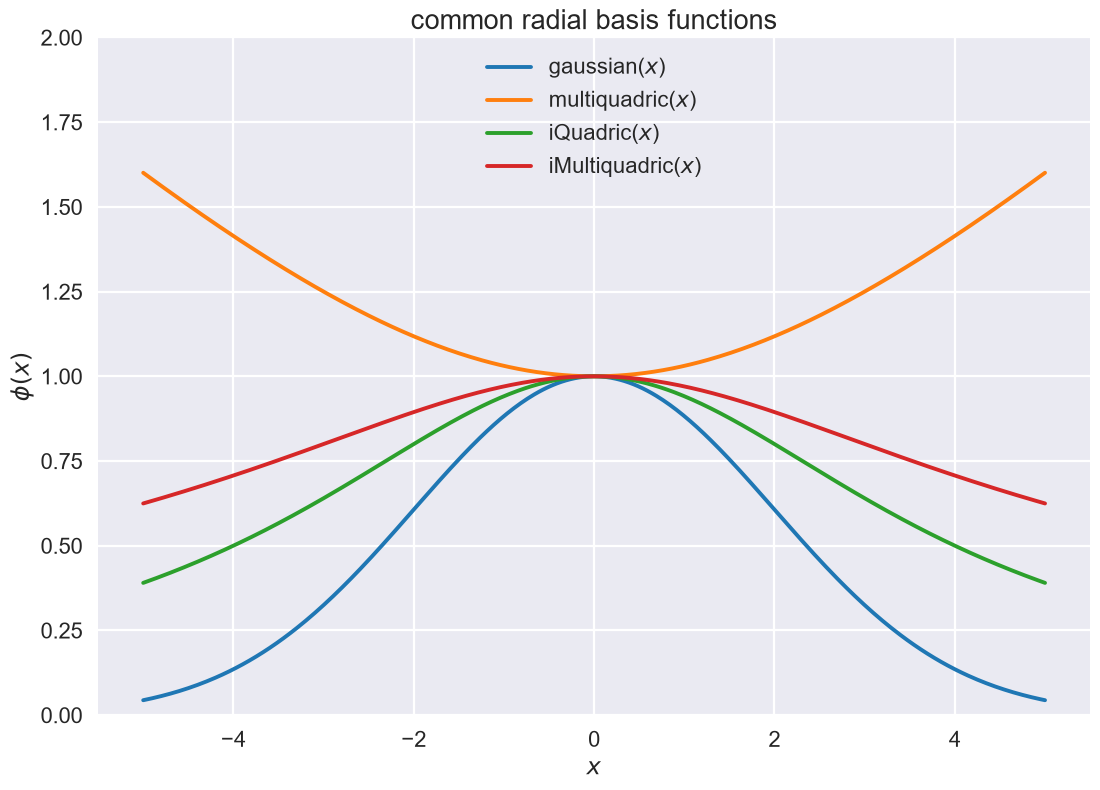

In [21]:
# PARAMETERS/CONSTANTS
L = 0.5 # lengthscale
e = 0.25 #epsilon


class MyKernel:
    def __init__(self, kernel_type='gaussian',
                 length_scale=0.2, epsilon=0.15):

        r"""
        Initialize the kernel.

        Parameters:
            kernel_type (str): The type of the kernel. Default is 'gaussian'.
            length_scale (float): The length scale parameter. Default is 0.2.
            epsilon (float): The epsilon parameter. Default is 0.15.

        """
        self.kernel_type = kernel_type
        self.length_scale = length_scale
        self.epsilon = epsilon


    def __call__(self, x: np.ndarray):
        r"""
        Evaluate the kernel function at the given points.

        Parameters:
            x (np.ndarray): The input points.
           

        Returns:
            np.ndarray: The kernel values at the given points.

        """
        ##### TODO: Enter your code here:
        if self.kernel_type == 'gaussian':
            return np.exp(-np.power(self.epsilon * x, 2) / (2 * self.length_scale ** 2))
        elif self.kernel_type == 'multiquadric':
            return np.sqrt(1 + np.power(self.epsilon * x, 2))
        elif self.kernel_type == 'inverse_quadric':
            return 1 / (1 + np.power(self.epsilon * x, 2))
        elif self.kernel_type == 'inverse_multiquadric':
            return 1 / (np.sqrt(1 + np.power(self.epsilon * x, 2)))
        else:
            raise ValueError(f"Unknown kernel type: {self.kernel_type}")
        ##### End of code

# Grid for plotting
x = np.linspace(-5, 5, 400)
# Distance from the center
r = np.absolute(x)

plt.plot(x, MyKernel('gaussian', length_scale=L, epsilon=e)(r), label = r'gaussian($x$)' )
plt.plot(x, MyKernel('multiquadric', length_scale=L, epsilon=e )(r), label = r'multiquadric($x$)' )
plt.plot(x, MyKernel('inverse_quadric', length_scale=L, epsilon=e)(r), label = r'iQuadric($x$)' )
plt.plot(x, MyKernel('inverse_multiquadric', length_scale=L, epsilon=e)(r), label = r'iMultiquadric($x$)' )

plt.title("common radial basis functions")
plt.ylim(0, 2)
plt.legend(loc="upper center")
plt.xlabel(r"$x$")
plt.ylabel(r"$\phi(x)$")
plt.show()

The following code snippet uses the implementation of a Gaussian Kernel from Scikit-Learn

Are the values close enough?  True


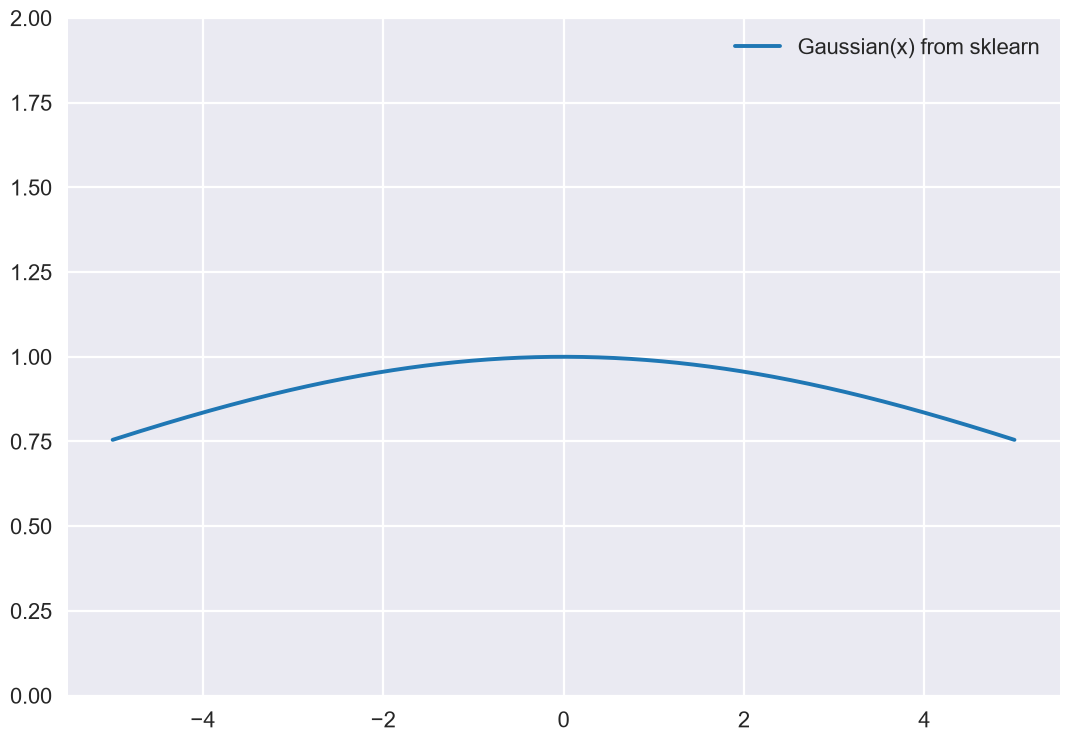

In [17]:
# Example of Gaussian kernel application from sklearn

from sklearn.gaussian_process.kernels import RBF


sklearn_gaussian = np.power(RBF(length_scale=L), e**2)
sklearn_gaussian_values, = sklearn_gaussian([[0,0]], np.column_stack((np.zeros(len(r)), r)))
our_gaussian_values = MyKernel('gaussian', length_scale=L, epsilon=e)(r)

# With the following line we check that the values computed by our function and the sklearn function 
# are close enough (within a tolerance of 1e-9)
print("Are the values close enough? ",np.isclose(sklearn_gaussian_values, our_gaussian_values, atol=1e-9).all())

plt.plot(x, sklearn_gaussian_values, label = 'Gaussian(x) from sklearn' )
plt.ylim(0, 2)
plt.legend(loc="upper right")
plt.show()

## Exercise 5
Define the method `compute_coefficients` below, which takes as input the vector of sample locations, the vector of sample observations, the name of the chosen rbf, and the norm method defined above, and gives back as output the list of coefficients (5 numbers because we have 5 points) of the linear combination giving the RBF approximation.

Suggestion: use `np.linalg.solve` to solve the linear matrix equation $Kw=y$, where $K$ is defined as:
$$ K =
\begin{bmatrix}
\varphi (\|\mathbf {x} _{1}-\mathbf {x} _{1}\|)&\varphi (\|\mathbf {x} _{2}-\mathbf {x} _{1}\|)&\dots &\varphi (\|\mathbf {x} _{n}-\mathbf {x} _{1}\|)\\\varphi (\|\mathbf {x} _{1}-\mathbf {x} _{2}\|)&\varphi (\|\mathbf {x} _{2}-\mathbf {x} _{2}\|)&\dots &\varphi (\|\mathbf {x} _{n}-\mathbf {x} _{2}\|)\\\vdots &\vdots &\ddots &\vdots \\\varphi (\|\mathbf {x} _{1}-\mathbf {x} _{n}\|)&\varphi (\|\mathbf {x} _{2}-\mathbf {x} _{n}\|)&\dots &\varphi (\|\mathbf {x} _{n}-\mathbf {x} _{n}\|)\\
\end{bmatrix}
$$

In [18]:
from typing import Callable
def compute_coefficients(xi:np.ndarray, 
                         fi:np.ndarray, 
                         rbf:Callable, 
                         norm:Callable)-> np.ndarray:
    r"""
    Compute the coefficients for radial basis function interpolation.

    Parameters:
        xi (np.ndarray): The known data points.
        fi (np.ndarray): The function values at the known data points.
        rbf (Callable): The radial basis function to use for interpolation.
        norm (Callable): The norm function to compute distances between points.

    Returns:
        np.ndarray: The coefficients for the radial basis function interpolation.
    """

    assert len(xi) == len(fi), "xi and fi must have the same length"
    assert isinstance(xi, np.ndarray), "xi must be a numpy array"
    assert isinstance(fi, np.ndarray), "fi must be a numpy array"
    assert callable(rbf), "rbf must be a callable function"
    assert callable(norm), "norm must be a callable function"

    ##### TODO: Enter your code here:
    size = len(xi)
    K = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            K[i, j] = rbf(norm(xi[i], xi[j]))
            
    return np.linalg.solve(K, fi)
     
    ##### End of code

# define our interpolation using list compression
def psi(x:np.ndarray, rbf:Callable, norm:Callable, xi:np.ndarray, fi:np.ndarray):
    r"""
    Compute the interpolated values at given points using radial basis function interpolation.
    Parameters:
        x (np.ndarray): The points at which to evaluate the interpolation.
        rbf (Callable): The radial basis function to use for interpolation.
        norm (Callable): The norm function to compute distances between points.
        xi (np.ndarray): The known data points.
        fi (np.ndarray): The function values at the known data points.

    Returns:
        np.ndarray: The interpolated values at the points in x.
    """
    wi = compute_coefficients(xi, fi, rbf, norm)
    return np.asarray([np.sum([wi_*rbf(norm(x_, xi_)) for xi_, wi_ in zip(xi, wi)]) for x_ in x])

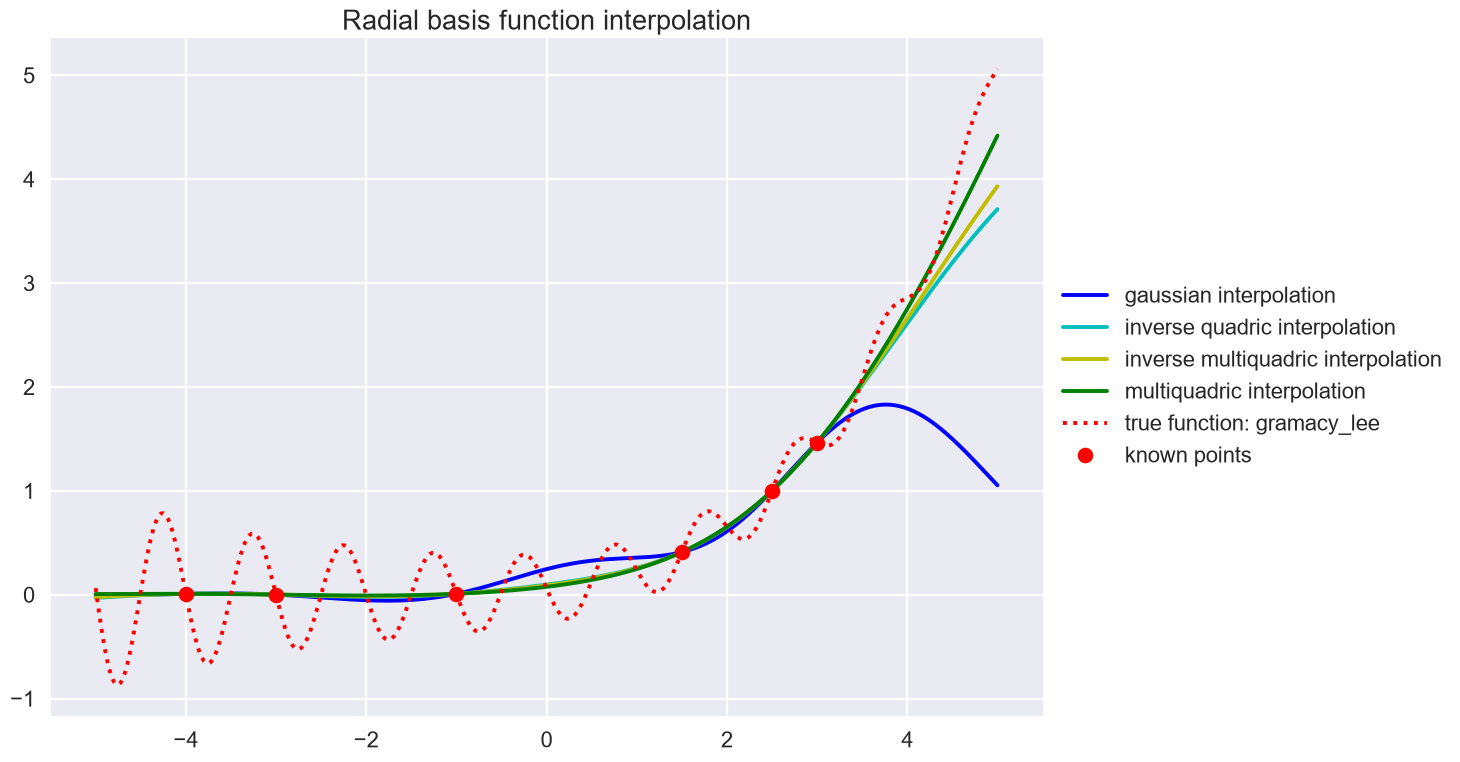

In [19]:
# We define our known points and their measurements
# We start with a 1D simple example

# Sampling locations
xi = np.atleast_2d([-4., -3., -1, 1.5, 2.5, 3]).T

# Sample observations
fi = f(xi).ravel()
    

plt.plot(x, psi(x, MyKernel('gaussian'), euclidean_norm, xi, fi), '-b', label = 'gaussian interpolation')
plt.plot(x, psi(x, MyKernel('inverse_quadric'), euclidean_norm, xi, fi), '-c', label = 'inverse quadric interpolation')
plt.plot(x, psi(x, MyKernel('inverse_multiquadric'), euclidean_norm, xi, fi), '-y', label = 'inverse multiquadric interpolation')
plt.plot(x, psi(x, MyKernel('multiquadric'), euclidean_norm, xi, fi), '-g', label = 'multiquadric interpolation')
plt.plot(x, f(x), 'r:', label= f'true function: {f.__name__}')
plt.plot(xi, fi, 'or', label = 'known points')

plt.title('Radial basis function interpolation')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

## Exercise 6
Run the following function by sweeping for different lengthscales and using different interpolation points. Record your observations and answer the following questions: 
- How is the prediction affected by using different lengthscales?
- What happens to the predictions if you sample wuth points really close to each other?

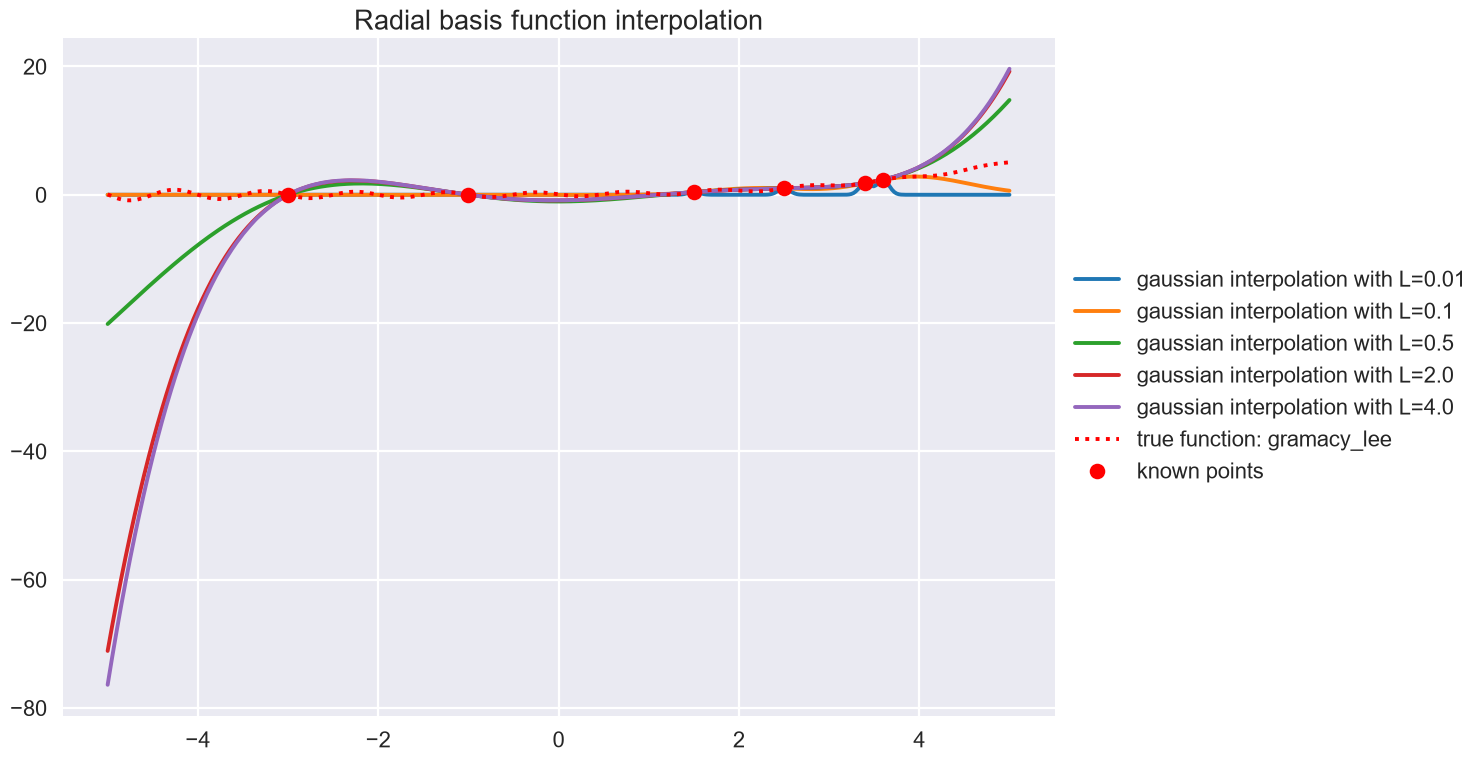

In [20]:
def approximation_different_lengthscales_sweep(x_trial:np.ndarray, 
                                               func:Callable, 
                                               length_scales:list, 
                                               rbf:str="gaussian", 
                                               norm:Callable=euclidean_norm, 
                                               epsilon:float=e,
                                               len_eval_points:int=400):
    r"""
    Compute and plot the interpolated values at given points using radial basis function interpolation
    for different length scales.

    Parameters:
        xi (np.ndarray): The known data points.
        fi (np.ndarray): The function values at the known data points.
        length_scales (list): A list of length scales to use for interpolation.
        rbf (str): The radial basis function to use for interpolation.
        norm (Callable): The norm function to compute distances between points.
        epsilon (float): The epsilon parameter for the radial basis function.
        len_eval_points (int): The number of points to evaluate the interpolation.
    """


    # Sample observations
    fi = func(x_trial).ravel()

    x = np.linspace(-5, 5, len_eval_points)

    for L in length_scales:
        plt.plot(x, psi(x, MyKernel(rbf, length_scale=L, epsilon=epsilon), norm, x_trial, fi), label = f'{rbf} interpolation with L={L}')    

    
    plt.plot(x, func(x), 'r:', label= f'true function: {func.__name__}')
    plt.plot(x_trial, fi, 'or', label = 'known points')

    plt.title('Radial basis function interpolation')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()


# TODO: Enter your code here by modifying the following line to use the function you want to approximate and the radial basis function you want to use for interpolation.
approximation_different_lengthscales_sweep(np.atleast_2d([ -3., -1, 1.5, 2.5, 3.4, 3.6]).T, f, 
                                           length_scales=[0.01,0.1, 0.5, 2.0, 4.0], 
                                           rbf="gaussian", norm=euclidean_norm, epsilon=e, len_eval_points=400)
# End of code
    